# CS383 — Assignment 2
## EDA and Visualization Report: NYC 311 Resolution Times

*Due: see LMS*

### Scenario
Your local Community Board office has asked you, as a data intern, to look into how long 311
complaints take to get resolved across the city. They need two things from you:

1. The supporting statistical analysis (distribution, outliers, borough comparison, correlation).
2. **One** short, plain-language write-up of a single finding that a board member — someone who has
   never opened a notebook or a spreadsheet — could read in thirty seconds and actually understand.

This is exactly the skill Lecture 5 built toward: doing the technical work, then translating it.

---

### Academic integrity and using AI

This assignment allows AI-assisted coding, the same way Lecture 5's Optional Challenge did — but the line is about *what* AI is allowed to do, not *whether* you can use it at all.

**Allowed** — using an AI tool (Claude, ChatGPT, GitHub Copilot, etc.) to help write the *mechanical* code in each deliverable's code cell: computing a statistic, building a chart, computing a correlation. You decide what needs to be computed; AI can help with how.

**Not allowed** — having AI write your reasoning, interpretation, or written answers. The outlier-cause reasoning (Deliverable 2), the borough comparison interpretation (Deliverable 3), the confounder you name (Deliverable 4), and the plain-language report (Deliverable 5) are the actual statistical judgment this assignment is testing. That judgment has to be yours.

**If you use AI for a code cell, add a one-line comment directly above it naming the prompt**, for example:

```python
# AI prompt: "write code to compute the IQR bounds for resolution_time_hours"
q1, q3 = ...
```

Only comment the lines that were actually AI-assisted — don't add it to code you wrote yourself.

A good test either way: if you can't explain — out loud, without looking anything up — exactly what every line of your submitted notebook does and *why it's the right computation for this question*, that's a sign you leaned on AI too much, whether or not you commented it.

---

### Getting started

Run the cell below once. It loads the same NYC 311 snapshot used in Lecture 5 (or realistic sample
data if the shared file isn't available). **Do not skip or modify this cell** — every deliverable
below assumes `complaints_df` exists with these columns.

In [108]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    raw_path = os.path.expanduser("~/shared/nyc311_snapshot.csv")
    complaints_df = pd.read_csv(raw_path).head(10000)
    complaints_df["created_date"] = pd.to_datetime(complaints_df["created_date"])
    complaints_df["closed_date"] = pd.to_datetime(complaints_df["closed_date"])
    live = True

except Exception:
    # Offline fallback, in case there is no internet connection in the room.
    rng = np.random.default_rng(383)
    n = 10000
    complaint_types = ["Noise - Residential", "Illegal Parking", "HEAT/HOT WATER",
                        "Blocked Driveway", "Street Condition", "Water System",
                        "PAINT/PLASTER", "Damaged Tree", "Sewer", "Rodent"]
    boroughs_list = ["MANHATTAN", "BROOKLYN", "QUEENS", "BRONX", "STATEN ISLAND"]
    agency_list = ["NYPD", "HPD", "DOB", "DSNY", "DOT", "DOHMH"]
    agency_p = [0.65, 0.15, 0.05, 0.05, 0.05, 0.05]

    n_days = 90
    days = pd.date_range("2026-01-01", periods=n_days, freq="D")
    day_weight = np.where(days.dayofweek >= 5, 0.6, 1.0)
    day_weight = day_weight / day_weight.sum()

    day_idx = rng.choice(n_days, size=n, p=day_weight)
    created = days[day_idx] + pd.to_timedelta(rng.integers(0, 24 * 60, size=n), unit="m")

    agency = rng.choice(agency_list, size=n, p=agency_p)
    is_nypd_fallback = agency == "NYPD"

    still_open = rng.random(n) < 0.15
    # NYPD dispatches and closes tickets same-day; other agencies (inspections,
    # scheduled follow-up) take much longer -- mirrors the real signal in the
    # live snapshot, so Deliverable 4 has something real to find offline too.
    resolution_hours = np.where(
        is_nypd_fallback,
        rng.gamma(shape=1.5, scale=0.8, size=n),
        rng.gamma(shape=2.0, scale=60.0, size=n),
    )
    closed = created + pd.to_timedelta(resolution_hours, unit="h")

    complaints_df = pd.DataFrame({
        "complaint_type": rng.choice(
            complaint_types, size=n,
            p=[0.18, 0.15, 0.14, 0.10, 0.10, 0.09, 0.08, 0.06, 0.05, 0.05],
        ),
        "borough": rng.choice(boroughs_list, size=n, p=[0.22, 0.32, 0.26, 0.16, 0.04]),
        "agency": agency,
        "created_date": created,
        "closed_date": np.where(still_open, pd.NaT, closed),
    })
    complaints_df["closed_date"] = pd.to_datetime(complaints_df["closed_date"])
    live = False

complaints_df["resolution_time_hours"] = (
    complaints_df["closed_date"] - complaints_df["created_date"]
).dt.total_seconds() / 3600
complaints_df["hour_filed"] = complaints_df["created_date"].dt.hour

print(f"{'Shared snapshot' if live else 'Offline fallback'} data: {len(complaints_df):,} 311 records")
complaints_df.head()

Shared snapshot data: 10,000 311 records


,unique_key,created_date,closed_date,agency,complaint_type,descriptor,location_type,incident_zip,incident_address,street_name,...,borough,status,resolution_description,community_board,open_data_channel_type,latitude,longitude,due_date,resolution_time_hours,hour_filed
0,68843617,2026-04-30 20:10:36,2026-05-06 23:04:54,HPD,DOOR/WINDOW,WINDOW FRAME,RESIDENTIAL BUILDING,10452.0,95 WEST 162 STREET,WEST 162 STREET,...,BRONX,Closed,HPD attempted to conduct an inspection in resp...,04 BRONX,PHONE,40.831393,-73.929322,NaN,146.905000,20
1,69542860,2026-06-30 22:01:12,2026-06-30 23:48:04,NYPD,Abandoned Vehicle,With License Plate,Street/Sidewalk,10001.0,7 AVENUE,7 AVENUE,...,MANHATTAN,Closed,The New York City Police Department responded ...,04 MANHATTAN,PHONE,40.744761,-73.995153,NaN,1.781111,22
2,67349425,2025-12-31 22:54:54,2025-12-31 23:37:37,NYPD,Noise - Residential,Loud Music/Party,Residential Building/House,11230.0,1571 EAST 3 STREET,EAST 3 STREET,...,BROOKLYN,Closed,The New York City Police Department responded ...,12 BROOKLYN,ONLINE,40.612198,-73.971478,NaN,0.711944,22
3,69919607,2026-07-31 23:02:58,2026-08-25 00:00:00,DOB,General Construction/Plumbing,Curb Cut/Driveway/Carport - Illegal,NaN,11219.0,1222 45 STREET,45 STREET,...,BROOKLYN,Closed,The Department of Buildings reviewed this comp...,12 BROOKLYN,UNKNOWN,40.638181,-73.991320,NaN,576.950556,23
4,69188560,2026-05-31 22:40:18,2026-06-01 04:06:53,NYPD,Illegal Parking,Posted Parking Sign Violation,Street/Sidewalk,10463.0,2655 NETHERLAND AVENUE,NETHERLAND AVENUE,...,BRONX,Closed,The New York City Police Department responded ...,08 BRONX,ONLINE,40.879042,-73.915291,NaN,5.443056,22


---

### Explore before you answer

Before jumping into the required questions, take a few minutes to look around:

- What does `complaints_df.describe()` show you about `resolution_time_hours`?
- How many complaints are still open (no `closed_date`) and therefore have no resolution time?
- Which boroughs and complaint types show up most often?

Use the scratch cell below (and add more cells if you want) to explore. This part isn't graded
directly, but it'll make the required questions much easier.

In [109]:
# Scratch space -- explore complaints_df here.
complaints_df.describe()

,unique_key,created_date,closed_date,incident_zip,latitude,longitude,resolution_time_hours,hour_filed
count,1.000000e+04,10000,9228,9940.000000,9852.000000,9852.000000,9228.000000,10000.000000
mean,6.863089e+07,2026-04-14 12:58:01.171800,2026-04-08 19:10:32.791504,10808.769014,40.741964,-73.920776,73.925779,21.342400
min,6.667343e+07,2025-10-31 21:06:18,2025-10-31 21:22:57,10000.000000,40.501852,-74.251363,0.000000,0.000000
25%,6.778876e+07,2026-01-31 21:02:33.250000,2026-01-04 02:55:40.250000,10452.000000,40.676688,-73.961884,0.716111,21.000000
50%,6.883505e+07,2026-04-30 20:04:01.500000,2026-04-01 17:18:30.500000,11201.000000,40.735645,-73.922625,2.237778,22.000000
75%,6.956094e+07,2026-06-30 23:57:16.750000,2026-07-01 01:33:03.250000,11235.000000,40.825361,-73.874851,17.124444,23.000000
max,7.029535e+07,2026-09-04 02:03:47,2026-09-04 02:22:24,11694.000000,40.912828,-73.706507,5306.219444,23.000000
std,1.196825e+06,NaN,NaN,534.959395,0.087748,0.073698,316.816136,3.071238


---

## Required Deliverable 1 — Distribution of Resolution Times (15 pts)

Compute the **mean**, **median**, and **standard deviation** of `resolution_time_hours` (drop missing
values first — those are complaints that are still open). Then make one histogram showing the shape of
the distribution.

In 1-2 sentences: is the distribution symmetric or skewed? What does that imply about whether the mean
or the median is the more honest way to describe a "typical" complaint's resolution time?

 Mean:  73.93 hours
 Median: 2.24 hours
 Std:   316.82


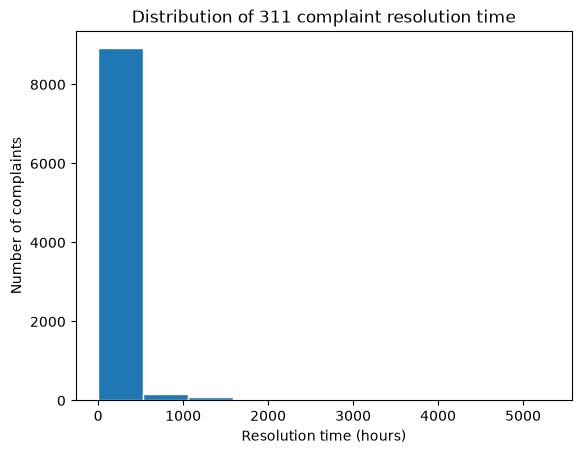

In [110]:
# Your code here.

# Removes all Null/NaN
complaints_df["resolution_time_hours"].dropna()

# Prints Mean, Median, STD
print(f" Mean:  {complaints_df["resolution_time_hours"].mean():.2f} hours")
print(f" Median: {complaints_df["resolution_time_hours"].median():.2f} hours")
print(f" Std:   {complaints_df["resolution_time_hours"].std():.2f}")

# Create a histogram
plt.hist(complaints_df["resolution_time_hours"], bins=10, edgecolor="white")
plt.xlabel("Resolution time (hours)")
plt.ylabel("Number of complaints")
plt.title("Distribution of 311 complaint resolution time")
plt.show()

**Your answer (symmetric or skewed, mean vs. median):**

This distribution is skewed. For skewed the median is the better way to describe typical resolution time because its less affected by outliers.


---

## Required Deliverable 2 — Flagging Outliers with the IQR Rule (15 pts)

Using the same 1.5×IQR rule from lecture, flag which resolution times count as outliers. Report the
IQR bounds and how many complaints get flagged.

**Before you write the code**, answer: do you think these flagged cases are more likely data-entry
errors, or real complaints that genuinely took an unusually long time? Justify your answer in 1-2
sentences.

**Your reasoning (before you code):**

I think the flagged cases will likely be real complaints that took unusually long.

In [111]:
# Your code here. 

# Calculates the IQR upper and lower bounds
q1, q3 = resolution_times.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"IQR: {iqr:.1f} hours") 

# Flag all outliers
outliers = complaints_df[
    (complaints_df["resolution_time_hours"] < lower_bound)
    | (complaints_df["resolution_time_hours"] > upper_bound)
]

print(f"Bounds: [{lower_bound:.1f}, {upper_bound:.1f}] hours")
print(f"{len(outliers):,} complaints flagged as outliers ({len(outliers) / len(resolution_times):.1%})")


IQR: 16.4 hours
Bounds: [-23.9, 41.7] hours
1,696 complaints flagged as outliers (18.4%)


In [112]:
outliers[["complaint_type", "borough", "resolution_time_hours"]].sort_values("resolution_time_hours", ascending=False)


,complaint_type,borough,resolution_time_hours
899,Building/Use,QUEENS,5306.219444
5208,General Construction/Plumbing,QUEENS,5305.815000
3535,Maintenance or Facility,QUEENS,5250.714167
670,Plumbing,BRONX,5091.052778
2675,APPLIANCE,MANHATTAN,5066.901667
...,...,...,...
410,HEAT/HOT WATER,MANHATTAN,42.020556
4984,Street Condition,MANHATTAN,41.991111
3159,HEAT/HOT WATER,MANHATTAN,41.915833
8253,HEAT/HOT WATER,BRONX,41.859167


---

## Required Deliverable 3 — Comparing Boroughs (15 pts)

Using a box plot, compare `resolution_time_hours` across the five boroughs. Which borough has the
**highest** median resolution time, and which has the **lowest**? Report the median for each, and
state the size of the gap between them in hours.

Note: a handful of rows have `borough` set to `"Unspecified"` rather than a real borough — filter
those out first, the same way you'd drop any row that doesn't answer the question being asked.

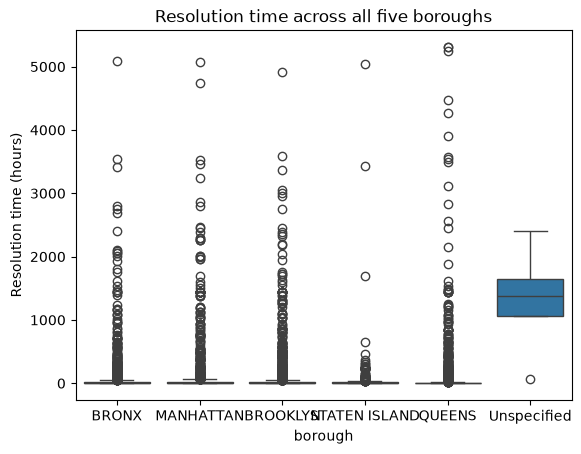

In [113]:
# Your code here.

# Removes boroughs with "Unspecified"
clean_df = complaints_df[complaints_df["borough"] != "Unspecified"]

# Creates a boxplot 
sns.boxplot(data=complaints_df, x="borough", y="resolution_time_hours")
plt.ylabel("Resolution time (hours)")
plt.title("Resolution time across all five boroughs")
plt.show()

In [114]:
# Median

# Removes boroughs with "Unspecified"
clean_df = complaints_df[complaints_df["borough"] != "Unspecified"]

# Finds the median resolution time for each borough
medians = complaints_df.groupby("borough")["resolution_time_hours"].median()
print(medians)

borough
BRONX               2.483611
BROOKLYN            2.064167
MANHATTAN           2.015000
QUEENS              2.520833
STATEN ISLAND       1.711944
Unspecified      1384.834028
Name: resolution_time_hours, dtype: float64


**Your answer (slowest / fastest borough, size of the gap):**

    The slowest borough is Queens with 2.5 median resolution time. The fastest borough is Staten Island with 1.7 median resolution time. The gap between the two is 0.8.


---

## Required Deliverable 4 — Correlation and a Causation Check (15 pts)

Create a new column `is_nypd` that is `1` when `agency == "NYPD"` and `0` otherwise. Compute the
correlation between `is_nypd` and `resolution_time_hours`.

This one comes out meaningfully different from zero — not just noise. Does that mean NYPD is simply
"better" or "faster" at its job than other agencies? Name **one plausible confounding variable** that
could explain most of this relationship without NYPD's efficiency directly causing it — the same kind
of check done for boroughs in Lecture 5's ice-cream/drowning example.

Note: some agencies only appear a handful of times in this data. An agency's median resolution time
isn't trustworthy if it's based on only a few complaints — the same problem as the `"Unspecified"`
borough in Deliverable 3. When you rank agencies, keep only agencies with at least 30 resolved
complaints.

In [115]:
# Your code here.

# Removes boroughs with "Unspecified"
clean_df = complaints_df[complaints_df["borough"] != "Unspecified"]

# Creates column "is_nypd" and labels 1 if its NYPD and 0 otherwise
complaints_df["is_nypd"] = complaints_df["agency"].map({"NYPD":1}).fillna(0).astype(int)

complaints_df[["agency", "is_nypd"]].head()


,agency,is_nypd
0,HPD,0
1,NYPD,1
2,NYPD,1
3,DOB,0
4,NYPD,1


In [116]:
# Correlation

complaints_df[["resolution_time_hours", "is_nypd"]].corr().round(3)

,resolution_time_hours,is_nypd
resolution_time_hours,1.000,-0.348
is_nypd,-0.348,1.000


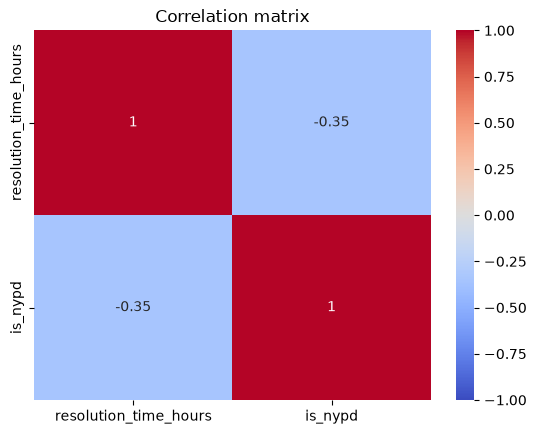

In [117]:
# Correlation heatmap

sns.heatmap(
    complaints_df[["resolution_time_hours", "is_nypd"]].corr(),
    annot=True, cmap="coolwarm", vmin=-1, vmax=1,
)
plt.title("Correlation matrix")
plt.show()

**Your answer (correlation strength + one plausible confounder):**
The correlation strength is -0.35. A plausible confounder is complaint type because certain types of complaints could take longer to complete than others.


---

## Required Deliverable 5 — The Non-Technical Report (30 pts)

Pick **one** finding from Deliverables 1-4 (or something else you noticed while exploring) that an
actual Community Board member — not a data scientist — would care about.

Using the four-part framework from lecture, write it up:

1. **Lead with the finding** — the one sentence a busy reader would actually remember.
2. **One supporting chart** — the smallest chart that proves the finding, not every chart you made.
3. **No jargon** — "IQR," "correlation," "standard deviation," and "outlier" mean nothing to this
   reader. Say what you found in plain language instead.
4. **State the "so what"** — why should this reader care? What would they do differently knowing this?

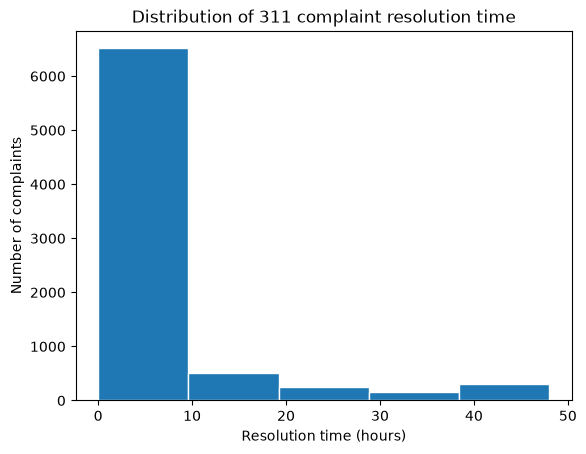

In [118]:
# Your code here.

# Removes all Null/NaN
complaints_df["resolution_time_hours"].dropna()

# Create a histogram
plt.hist(complaints_df["resolution_time_hours"], bins=5, range=(0, 48), edgecolor="white")
plt.xlabel("Resolution time (hours)")
plt.ylabel("Number of complaints")
plt.title("Distribution of 311 complaint resolution time")
plt.show()

**Your report (plain language):**
    The resolution time for most complaints are short. This means that some complaints might be taking longer than it should. They should find the reason the resolution time for complaints takes longer than other complaints so they could solve any issues that increased the resolution time.
    

---

### AI Check

In 1-2 sentences: identify one line of AI-generated code you used in this assignment and how you verified it was correct **for this specific dataset** (remember, the data might come from the live snapshot or the offline fallback, and columns like `agency` are unevenly represented). If you didn't use AI this time, just note that.

**Your answer:**

No AI used.

---

## Grading Rubric

| Criterion | Points |
|---|---|
| Deliverable 1 — stats computed correctly; histogram shown; skew/mean-vs-median answer is correct | 15 |
| Deliverable 2 — IQR bounds and outlier count correct; reasoning is stated and defensible | 15 |
| Deliverable 3 — box plot correct; slowest/fastest borough and gap correctly identified | 15 |
| Deliverable 4 — correlation computed correctly; confounder is plausible and genuinely independent | 15 |
| Deliverable 5 — finding is genuinely non-technical, chart is the *right* one, "so what" is present | 30 |
| Notebook runs top to bottom without errors | 10 |
| **Total** | **100** |

---

## Submission

### GitHub (same repo as Assignment 1)

1. Use the same `cs383-assignments` repo you created for Assignment 1. Inside it, create a new folder:
   `assignment2/`.
2. Put your completed notebook in that folder, keeping its original filename:
   `assignment2_311_eda_report.ipynb`.

```bash
git add -A
git commit -m "Assignment 2: 311 EDA report"
git push
```

Submit the **direct link to your notebook file on GitHub** (the URL should end in
`assignment2/assignment2_311_eda_report.ipynb`) on BrightSpace under **Assignment 2**.

Make sure your notebook runs top to bottom without errors before you submit — a notebook that only
works because cells were run out of order will not be graded as passing.